In [54]:
import numpy as np
import os
import sys
import matplotlib.pyplot as plt
import cv2

sys.path.append("..")
from tflite_inference import TFLiteInferer

%load_ext autoreload
%autoreload 2

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


In [55]:
def draw_output(img, output):
    tmp = img.copy()
    for box in output:
        x1, y1, w, h, conf, _, x, y = box
        x2 = x1 + w
        y2 = y1 + h
        cv2.rectangle(tmp, (int(x1), int(y1)), (int(x2), int(y2)), (0, 255, 0), 2)
        cv2.circle(tmp, (int(x), int(y)), 9, (0, 255, 0), -1)
        cv2.putText(tmp, f"{conf:.2f}", (int(x1), int(y1 - 10)), cv2.FONT_HERSHEY_SIMPLEX, 0.5, (0, 255, 0), 2)
    plt.imshow(tmp)

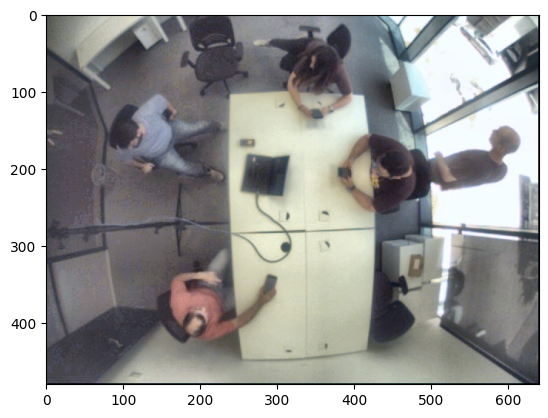

In [56]:
img_pth = "/home/klymy/data/cam4_revB/yolo_dataset/batch1_5_margin_15_bg_wb_alif_clahe/images/val/4.2_batch2____4.2_H_cam_262_spacesMR_201.jpg"
img = cv2.imread(img_pth)
img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
plt.imshow(img)

In [57]:
base_model = TFLiteInferer(
    yolo_pth="best_saved_model/best_full_integer_quant.tflite",
    head_pth="head_saved_model/head_float32.tflite",
    conf_th=0.20
)

In [58]:
output = base_model.infer(img)
output

array([[304.98034668,  37.86342239,  97.81918335,  99.75923157,
          0.86289454,   0.        , 356.30795288, 102.03691101],
       [ 78.78046417, 104.32347107, 158.68475342, 117.25883484,
          0.86289454,   0.        , 164.30796814, 171.22377014],
       [377.5944519 , 152.6075592 , 104.8449707 , 109.30787659,
          0.86289454,   0.        , 423.76586914, 208.41061401],
       [479.35888672, 141.08995056, 141.16308594,  90.38398743,
          0.86289454,   0.        , 492.13146973, 204.95272827],
       [158.76020813, 295.09973145, 140.4584198 , 133.61968994,
          0.86289454,   0.        , 224.85006714, 356.30795288]])

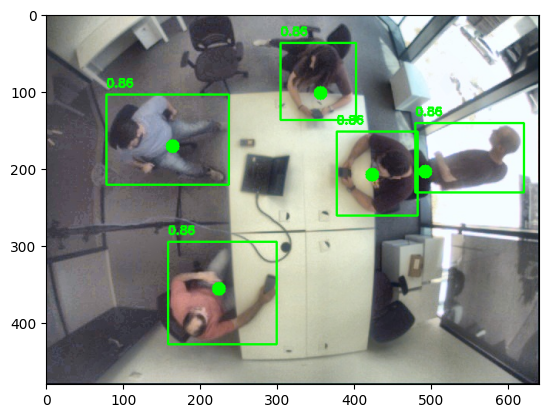

In [59]:
draw_output(img, output)

In [81]:
sep_model = TFLiteInferer(
    yolo_pth="best_saved_model/best_full_integer_quant.tflite",
    head_pth="head_uint8_saved_model/head_float32.tflite",
    conf_th=0.20,
    separated_head=True
)

TensorFlow version:  2.17.0


In [82]:
output = sep_model.infer(img)
output

array([[304.98034668,  37.86342239,  97.81918335,  99.75923157,
          0.86289454,   0.        , 356.30795288, 102.03691101],
       [ 78.78046417, 104.32347107, 158.68475342, 117.25883484,
          0.86289454,   0.        , 164.30796814, 171.22377014],
       [377.5944519 , 152.6075592 , 104.8449707 , 109.30787659,
          0.86289454,   0.        , 423.76586914, 208.41061401],
       [479.35888672, 141.08995056, 141.16308594,  90.38398743,
          0.86289454,   0.        , 492.13146973, 204.95272827],
       [158.76020813, 295.09973145, 140.4584198 , 133.61968994,
          0.86289454,   0.        , 224.85006714, 356.30795288]])

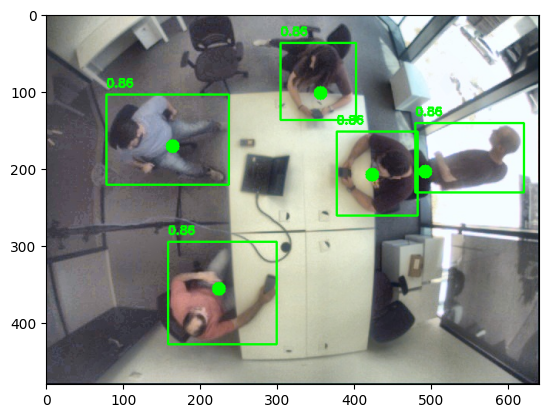

In [83]:
draw_output(img, output)

In [84]:
sep_quant_model = TFLiteInferer(
    yolo_pth="best_saved_model/best_full_integer_quant.tflite",
    head_pth="head_uint8_saved_model_100/head_full_integer_quant.tflite",
    conf_th=0.35,
    separated_head=True,
    head_int8=True,
    # idxs=[1, 6, 4, 3, 2, 5, 0]  # Adjust the indices based on your model's output structure
)

In [85]:
output = sep_quant_model.infer(img)
output

array([[366.65283203,   0.        ,   0.        , 122.21761322,
          0.84375   ,   0.        , 366.65283203,  84.02461243],
       [244.43522644,   0.        , 122.21761322, 122.21761322,
          0.84375   ,   0.        , 366.65283203, 122.21761322],
       [122.21761322, 122.21761322, 122.21761322, 122.21761322,
          0.84375   ,   0.        , 160.41061401, 160.41061401],
       [366.65283203, 122.21761322, 122.21761322, 122.21761322,
          0.84375   ,   0.        , 412.48443604, 206.24221802],
       [488.87045288, 122.21761322, 122.21761322, 122.21761322,
          0.84375   ,   0.        , 488.87045288, 206.24221802],
       [122.21761322, 244.43522644, 122.21761322, 122.21761322,
          0.84375   ,   0.        , 206.24221802, 366.65283203],
       [305.54403687,  61.10880661, 122.21761322,  61.10880661,
          0.78125   ,   0.        , 374.29144287, 106.94041443],
       [122.21761322, 244.43522644, 122.21761322, 244.43522644,
          0.78125   ,   0.       

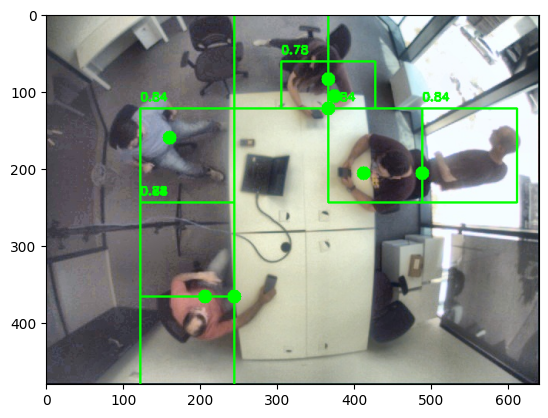

In [86]:
draw_output(img, output)

In [87]:
sep_quant_model = TFLiteInferer(
    yolo_pth="best_saved_model/best_full_integer_quant.tflite",
    head_pth="head_uint8_saved_model_200/head_full_integer_quant.tflite",
    conf_th=0.35,
    separated_head=True,
    head_int8=True,
    # idxs=[1, 6, 4, 3, 2, 5, 0]  # Adjust the indices based on your model's output structure
)

In [88]:
output = sep_quant_model.infer(img)
output

array([[366.5140686 ,   0.        ,   0.        , 122.1713562 ,
          0.85546875,   0.        , 366.5140686 ,  83.99280548],
       [244.3427124 ,   0.        , 122.1713562 , 122.1713562 ,
          0.85546875,   0.        , 366.5140686 , 122.1713562 ],
       [122.1713562 , 122.1713562 , 122.1713562 , 122.1713562 ,
          0.85546875,   0.        , 167.98561096, 167.98561096],
       [366.5140686 , 122.1713562 , 122.1713562 , 122.1713562 ,
          0.85546875,   0.        , 412.32833862, 206.16416931],
       [488.6854248 , 122.1713562 , 122.1713562 , 122.1713562 ,
          0.85546875,   0.        , 496.32113647, 206.16416931],
       [122.1713562 , 244.3427124 , 122.1713562 , 244.3427124 ,
          0.85546875,   0.        , 206.16416931, 366.5140686 ],
       [122.1713562 , 244.3427124 , 122.1713562 , 122.1713562 ,
          0.85546875,   0.        , 206.16416931, 366.5140686 ],
       [305.42840576,  61.0856781 , 122.1713562 ,  61.0856781 ,
          0.79296875,   0.       

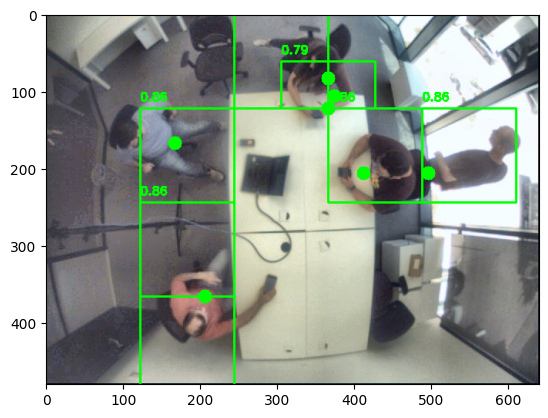

In [89]:
draw_output(img, output)

In [72]:
sep_quant_model = TFLiteInferer(
    yolo_pth="best_saved_model/best_full_integer_quant.tflite",
    head_pth="head_uint8_saved_model_300/head_full_integer_quant.tflite",
    conf_th=0.35,
    separated_head=True,
    head_int8=True,
    # idxs=[1, 6, 4, 3, 2, 5, 0]  # Adjust the indices based on your model's output structure
)

In [73]:
output = sep_quant_model.infer(img)
output

array([[366.52484131,   0.        ,   0.        , 122.17494965,
          0.85546875,   0.        , 366.52484131,  83.9952774 ],
       [244.34989929,   0.        , 122.17494965, 122.17494965,
          0.85546875,   0.        , 366.52484131, 122.17494965],
       [122.17494965, 122.17494965, 122.17494965, 122.17494965,
          0.85546875,   0.        , 167.99055481, 167.99055481],
       [366.52484131, 122.17494965, 122.17494965, 122.17494965,
          0.85546875,   0.        , 412.3404541 , 206.17022705],
       [488.69979858, 122.17494965, 122.17494965, 122.17494965,
          0.85546875,   0.        , 496.33572388, 206.17022705],
       [122.17494965, 244.34989929, 122.17494965, 244.34989929,
          0.85546875,   0.        , 206.17022705, 366.52484131],
       [122.17494965, 244.34989929, 122.17494965, 122.17494965,
          0.85546875,   0.        , 206.17022705, 366.52484131],
       [305.43737793,  61.08747482, 122.17494965,  61.08747482,
          0.7890625 ,   0.       

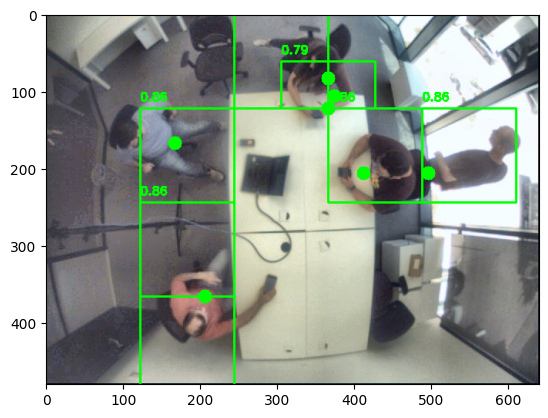

In [74]:
draw_output(img, output)

In [75]:
sep_quant_model = TFLiteInferer(
    yolo_pth="best_saved_model/best_full_integer_quant.tflite",
    head_pth="head_uint8_saved_model_400/head_full_integer_quant.tflite",
    conf_th=0.35,
    separated_head=True,
    head_int8=True,
    # idxs=[1, 6, 4, 3, 2, 5, 0]  # Adjust the indices based on your model's output structure
)

In [76]:
output = sep_quant_model.infer(img)
output

array([[366.48727417,   0.        ,   0.        , 122.16242218,
          0.85546875,   0.        , 366.48727417,  83.98666382],
       [244.32484436,   0.        , 122.16242218, 122.16242218,
          0.85546875,   0.        , 366.48727417, 122.16242218],
       [122.16242218, 122.16242218, 122.16242218, 122.16242218,
          0.85546875,   0.        , 167.97332764, 167.97332764],
       [366.48727417, 122.16242218, 122.16242218, 122.16242218,
          0.85546875,   0.        , 412.29818726, 206.14909363],
       [488.64968872, 122.16242218, 122.16242218, 122.16242218,
          0.85546875,   0.        , 496.28485107, 206.14909363],
       [122.16242218, 244.32484436, 122.16242218, 244.32484436,
          0.85546875,   0.        , 206.14909363, 366.48727417],
       [122.16242218, 244.32484436, 122.16242218, 122.16242218,
          0.85546875,   0.        , 206.14909363, 366.48727417],
       [305.40606689,  61.08121109, 122.16242218,  61.08121109,
          0.7890625 ,   0.       

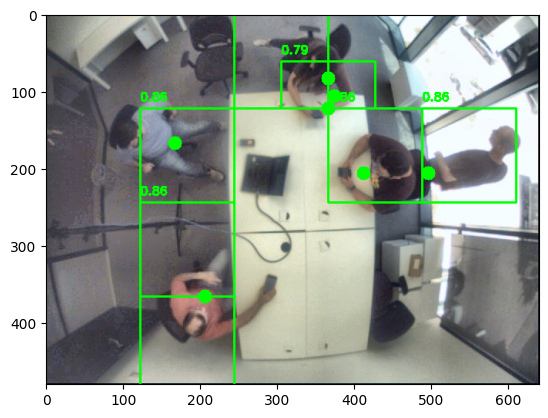

In [77]:
draw_output(img, output)

In [101]:
import onnxruntime as ort
import numpy as np

In [92]:
# Load the merged model
session = ort.InferenceSession("combined.onnx", providers=["CPUExecutionProvider"])

In [93]:
input_name = session.get_inputs()[0].name
input_name

'images'

In [115]:
input_data = sep_quant_model.pre_process(img)
input_data.shape
input_data = np.transpose(input_data, (0, 3, 1, 2)).astype(np.float32) / 255  # Ensure the input is in float32 format

In [116]:
bboxes, scores = session.run(None, {input_name: input_data})

In [117]:
outputs = np.concatenate([bboxes[:, :, :4], scores, bboxes[:, :, 4:]], axis=-1)
outputs.shape

(1, 2100, 7)

In [118]:
detections = sep_quant_model.post_process(outputs)
detections.shape

(5, 8)

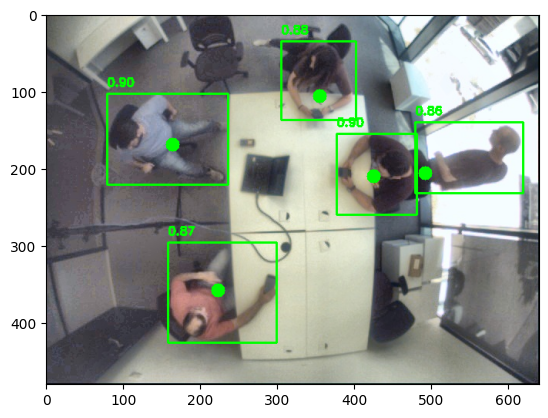

In [119]:
draw_output(img, detections)